In [16]:
# The purpose of this notebook is to expand the search space for the candidate formulas and see if we can find 
# anything better than what we have already gotton

In [17]:
# import the data

from pathlib import Path
import pandas as pd

# Load the compiled data
project_root = Path.cwd().resolve().parent if 'notebooks' in str(Path.cwd()) else Path.cwd().resolve()
excel_path = project_root / 'data' / 'raw' / 'Compiled Data.xlsx'

df = pd.read_excel(excel_path)

formula_cols = ["TEM", "Joncryl", "NC513", "PEG-DE", "NGDE"]
measured_target_cols = [
    "Avg_Density_g_cm3",
    "24h_avg_pct absorption",
    "24h_avg_pct_retention",
]
measured_se_cols = [
    "Avg_Density SE",
    "24h_se.1",
    "24h_se",
]

# Keep each target beside its standard error column
measured_cols = [
    col
    for target, se in zip(measured_target_cols, measured_se_cols)
    for col in (target, se)
]
df = df.loc[:, formula_cols + measured_cols]
df = df.rename(columns={
    "24h_se.1": "se_absorption",
    "24h_se": "se_retention",
})

print(df.head())

   TEM  Joncryl  NC513  PEG-DE  NGDE  Avg_Density_g_cm3  Avg_Density SE  \
0    8      NaN    NaN     NaN   NaN           0.192000        0.002667   
1    8      0.7    NaN     NaN   NaN           0.195000        0.007263   
2    8      1.0    NaN     NaN   NaN           0.159000        0.005033   
3    8      1.5    NaN     NaN   NaN           0.159933        0.004410   
4    8      2.0    NaN     NaN   NaN           0.201000        0.008817   

   24h_avg_pct absorption  se_absorption  24h_avg_pct_retention  se_retention  
0              113.616943       5.271375                  31.77          2.81  
1              103.817309       3.496766                  33.12          2.57  
2              129.464292       5.490086                  36.25          1.77  
3              120.749405       2.660519                  25.33          0.38  
4              113.871581       2.071998                  26.58          0.99  


In [18]:
# get the 100,000 candidate formulas, they are stored in candidate_set

# Formula constraints:
# - TEM: 3-30%.
# - Each chain extender (Joncryl, NC513, PEG-DE, NGDE): 0.7-5% when included; 0% when omitted.
# - Combined chain extender amount: no more than 9%.
# - Generate 100,000 valid candidate formulas.

import numpy as np
import pandas as pd

candidate_count = 100_000
chain_extender_cols = ["Joncryl", "NC513", "PEG-DE", "NGDE"]
feature_cols = ["TEM", *chain_extender_cols]
rng = np.random.default_rng(42)

candidate_chunks = []
collected = 0
while collected < candidate_count:
    batch_size = max(10_000, 2 * (candidate_count - collected))
    active_counts = rng.integers(1, len(chain_extender_cols) + 1, size=batch_size)
    active_order = rng.random((batch_size, len(chain_extender_cols))).argsort(axis=1)
    active_mask = active_order < active_counts[:, None]
    extender_amounts = rng.uniform(0.7, 5.0, size=(batch_size, len(chain_extender_cols)))
    extender_amounts = np.where(active_mask, extender_amounts, 0.0)

    valid_mask = extender_amounts.sum(axis=1) <= 9.0
    valid_batch = extender_amounts[valid_mask]
    candidate_chunks.append(valid_batch)
    collected += len(valid_batch)

extender_values = np.concatenate(candidate_chunks, axis=0)[:candidate_count]
candidate_set = pd.DataFrame(extender_values, columns=chain_extender_cols)
candidate_set.insert(0, "TEM", rng.uniform(3.0, 30.0, size=candidate_count))
candidate_set = candidate_set[feature_cols]

# Confirm the generated formulas satisfy every requested bound.
assert len(candidate_set) == candidate_count
assert candidate_set["TEM"].between(3.0, 30.0).all()
assert candidate_set[chain_extender_cols].sum(axis=1).le(9.0).all()
for col in chain_extender_cols:
    active = candidate_set[col].ne(0)
    assert candidate_set.loc[active, col].between(0.7, 5.0).all()

print(f"Generated {len(candidate_set):,} valid candidate formulas.")
print(candidate_set.head())
print("Maximum total chain extender:", candidate_set[chain_extender_cols].sum(axis=1).max())

Generated 100,000 valid candidate formulas.
         TEM   Joncryl     NC513    PEG-DE      NGDE
0  25.484578  0.000000  0.000000  3.501826  0.000000
1  18.407481  2.728296  0.862686  1.659987  0.746673
2   7.553238  0.981372  3.073936  4.819221  0.000000
3  10.545875  4.013331  0.000000  1.559579  0.000000
4   9.618866  3.371375  0.000000  0.000000  0.870197
Maximum total chain extender: 8.999925244360941


In [ ]:
# get predictions and predictive uncertainty for these formulas

import joblib
from pathlib import Path

project_root = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
models_dir = project_root / "models"
gpr_models = joblib.load(models_dir / "gpr_models.joblib")

feature_cols = ["TEM", "Joncryl", "NC513", "PEG-DE", "NGDE"]
X_candidates = candidate_set.loc[:, feature_cols]

batch_size = 5_000
prediction_batches = {name: {"mean": [], "std": []} for name in gpr_models}

for name, model in gpr_models.items():
    for start in range(0, len(X_candidates), batch_size):
        batch = X_candidates.iloc[start : start + batch_size]
        mean_batch, std_batch = model.predict(batch, return_std=True)
        prediction_batches[name]["mean"].append(mean_batch)
        prediction_batches[name]["std"].append(std_batch)

prediction_columns = {}
for name, batches in prediction_batches.items():
    prediction_columns[f"pred_{name}"] = np.concatenate(batches["mean"])
    prediction_columns[f"std_{name}"] = np.concatenate(batches["std"])

predictions = pd.DataFrame(prediction_columns, index=candidate_set.index)
candidate_predictions = pd.concat([candidate_set, predictions], axis=1)

required_std_cols = [f"std_{name}" for name in gpr_models]
missing_std_cols = [col for col in required_std_cols if col not in candidate_predictions.columns]
if missing_std_cols:
    raise KeyError(f"Prediction standard-deviation columns were not created: {missing_std_cols}")

display(candidate_predictions[feature_cols + [f"pred_{name}" for name in gpr_models]].head())


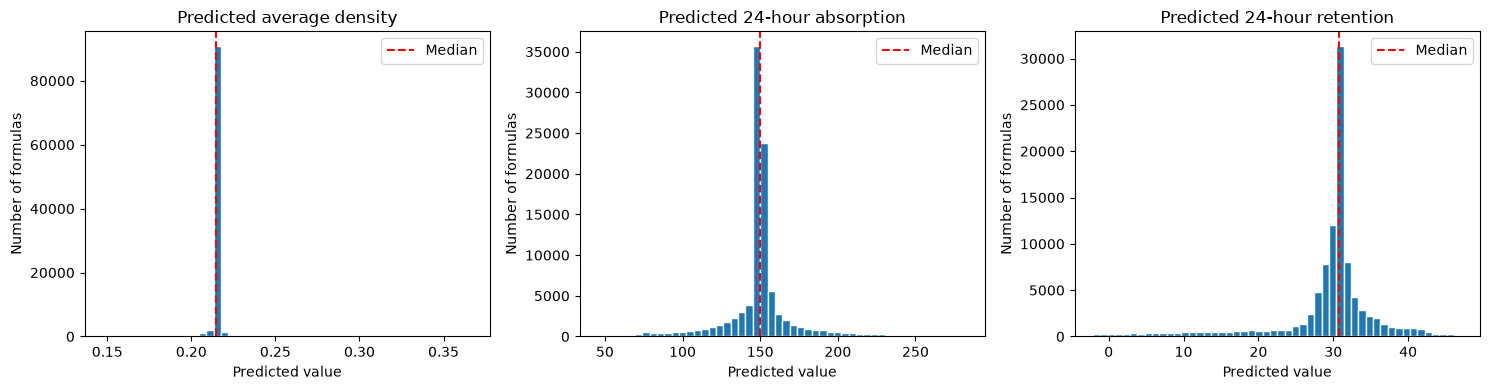

In [20]:
# get histograms of the predictions for the 3 properties for the 100,000 formulas in candidate set

import matplotlib.pyplot as plt

prediction_cols = [
    "pred_Avg_Density_g_cm3",
    "pred_24h_avg_pct absorption",
    "pred_24h_avg_pct_retention",
]

plot_titles = [
    "Predicted average density",
    "Predicted 24-hour absorption",
    "Predicted 24-hour retention",
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col, title in zip(axes, prediction_cols, plot_titles):
    values = candidate_predictions[col].dropna()
    ax.hist(values, bins=50, edgecolor="white")
    ax.set_title(title)
    ax.set_xlabel("Predicted value")
    ax.set_ylabel("Number of formulas")
    ax.axvline(values.median(), color="red", linestyle="--", label="Median")
    ax.legend()

fig.tight_layout()
plt.show()

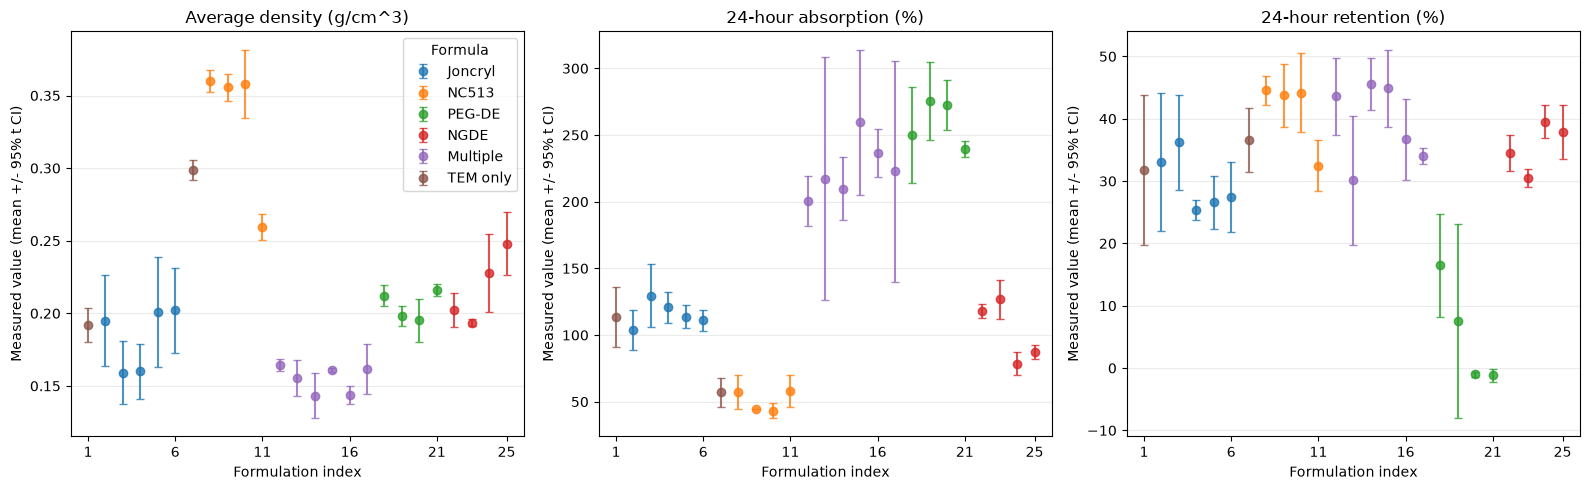

In [21]:
# Plot each formulation's measured mean and 95 CI, colored by formula.
import matplotlib.pyplot as plt
import numpy as np

target_se_pairs = {
    "Avg_Density_g_cm3": "Avg_Density SE",
    "24h_avg_pct absorption": "se_absorption",
    "24h_avg_pct_retention": "se_retention",
}

target_labels = {
    "Avg_Density_g_cm3": "Average density (g/cm^3)",
    "24h_avg_pct absorption": "24-hour absorption (%)",
    "24h_avg_pct_retention": "24-hour retention (%)",
}
ingredient_cols = ["Joncryl", "NC513", "PEG-DE", "NGDE"]
ingredient_presence = df[ingredient_cols].notna() & df[ingredient_cols].ne(0)
ingredient_count = ingredient_presence.sum(axis=1)

df["formula_group"] = "TEM only"
df.loc[ingredient_count > 1, "formula_group"] = "Multiple"
single_ingredient = ingredient_count == 1
df.loc[single_ingredient, "formula_group"] = ingredient_presence.loc[single_ingredient].idxmax(axis=1)

formula_groups = [
    group
    for group in ingredient_cols + ["Multiple", "TEM only"]
    if group in df["formula_group"].values
]
formula_colors = dict(zip(formula_groups, plt.get_cmap("tab10").colors))

fig, axes = plt.subplots(1, len(target_se_pairs), figsize=(16, 5), sharex=True)

for ax, target in zip(axes, target_se_pairs):
    se_col = target_se_pairs[target]
    plot_data = df[[target, se_col, "formula_group"]].dropna(
        subset=[target, se_col]
    )

    for group in formula_groups:
        group_data = plot_data.loc[plot_data["formula_group"] == group]
        means = group_data[target].to_numpy()
        standard_errors = group_data[se_col].to_numpy()
        n = 3
        degrees_of_freedom = n - 1
        t_critical_95 = 4.302652729911275  # t_(0.975, df=2)
        ci_95_half_width = t_critical_95 * standard_errors
        formulation_indices = group_data.index.to_numpy() + 1

        ax.errorbar(
            formulation_indices,
            means,
            yerr=ci_95_half_width,
            fmt="o",
            capsize=3,
            alpha=0.8,
            color=formula_colors[group],
            label=group,
        )

    ax.set_title(target_labels[target])
    ax.set_xlabel("Formulation index")
    ax.set_ylabel("Measured value (mean +/- 95% t CI)")
    ax.set_xlim(0, len(df) + 1)
    ax.set_xticks(np.unique(np.append(np.arange(1, len(df) + 1, 5), len(df))))
    ax.grid(axis="y", alpha=0.25)

axes[0].legend(title="Formula")
fig.tight_layout()
plt.show()

In [ ]:
# Find Pareto-optimal formulas for low density and high absorption/retention.
# Rank the frontier by equal-weight distance to the normalized ideal; model standard deviations are not used.

objective_cols = [
    "pred_Avg_Density_g_cm3",
    "pred_24h_avg_pct absorption",
    "pred_24h_avg_pct_retention",
]
objective_values = candidate_predictions[objective_cols].to_numpy(dtype=float)
if not np.isfinite(objective_values).all():
    raise ValueError("Candidate objective predictions contain missing or non-finite values.")

density = objective_values[:, 0]
absorption = objective_values[:, 1]
retention = objective_values[:, 2]

# Sweep from lower to higher density and use a Fenwick tree to test whether
# a candidate is dominated by one with at least as much absorption/retention.
absorption_levels = np.unique(absorption)
tree = np.full(len(absorption_levels) + 1, -np.inf)
pareto_mask = np.zeros(len(candidate_predictions), dtype=bool)
candidate_indices = np.arange(len(candidate_predictions))
order = np.lexsort((candidate_indices, -retention, -absorption, density))

for row in order:
    absorption_rank = np.searchsorted(absorption_levels, absorption[row])
    reversed_rank = len(absorption_levels) - absorption_rank

    best_retention = -np.inf
    position = reversed_rank
    while position > 0:
        best_retention = max(best_retention, tree[position])
        position -= position & -position

    if best_retention < retention[row]:
        pareto_mask[row] = True

    position = reversed_rank
    while position < len(tree):
        tree[position] = max(tree[position], retention[row])
        position += position & -position

candidate_predictions["pareto_optimal"] = pareto_mask

# Scale each objective to [0, 1] over all candidates, with 1 always best.
objective_ranges = np.array([
    density.max() - density.min(),
    absorption.max() - absorption.min(),
    retention.max() - retention.min(),
])
if np.any(objective_ranges <= 0):
    raise ValueError("Cannot balance objectives because at least one prediction is constant.")
objective_benefits = np.column_stack([
    (density.max() - density) / objective_ranges[0],
    (absorption - absorption.min()) / objective_ranges[1],
    (retention - retention.min()) / objective_ranges[2],
])
candidate_predictions["balance_distance"] = np.sqrt(
    np.mean((1.0 - objective_benefits) ** 2, axis=1)
)

# Flag candidates outside any fitted model's per-feature training bounds.
outside_training_range = np.zeros(len(candidate_predictions), dtype=bool)
for model in gpr_models.values():
    scaler = model.named_steps["standardscaler"]
    regressor = model.named_steps["gaussianprocessregressor"]
    X_train = scaler.inverse_transform(regressor.X_train_)
    for i, feature in enumerate(feature_cols):
        outside_training_range |= (
            (candidate_predictions[feature].to_numpy() < X_train[:, i].min())
            | (candidate_predictions[feature].to_numpy() > X_train[:, i].max())
        )
candidate_predictions["outside_training_range"] = outside_training_range

top_50_candidates = (
    candidate_predictions.loc[candidate_predictions["pareto_optimal"]]
    .sort_values("balance_distance", ascending=True)
    .head(50)
    .copy()
)

if len(top_50_candidates) < 50:
    raise ValueError(
        f"Only {len(top_50_candidates)} Pareto-optimal formulas were found; cannot return 50."
    )

print("Top 50 Pareto-optimal formulas, balanced across density, absorption, and retention:")
display(
    top_50_candidates.assign(rank=np.arange(1, len(top_50_candidates) + 1))[
        ["rank", *feature_cols, *objective_cols, "balance_distance"]
    ]
)


In [ ]:
# Compare measured formulation means and 95% confidence intervals with
# top_50_candidates' predicted means and GPR standard deviations.

import matplotlib.pyplot as plt
import numpy as np
target_se_pairs = {
    "Avg_Density_g_cm3": "Avg_Density SE",
    "24h_avg_pct absorption": "se_absorption",
    "24h_avg_pct_retention": "se_retention",
}

target_labels = {
    "Avg_Density_g_cm3": "Average density (g/cm^3)",
    "24h_avg_pct absorption": "24-hour absorption (%)",
    "24h_avg_pct_retention": "24-hour retention (%)",
}
ingredient_cols = ["Joncryl", "NC513", "PEG-DE", "NGDE"]
ingredient_presence = df[ingredient_cols].notna() & df[ingredient_cols].ne(0)
ingredient_count = ingredient_presence.sum(axis=1)

df["formula_group"] = "TEM only"
df.loc[ingredient_count > 1, "formula_group"] = "Multiple"
single_ingredient = ingredient_count == 1
df.loc[single_ingredient, "formula_group"] = ingredient_presence.loc[single_ingredient].idxmax(axis=1)

formula_groups = [
    group
    for group in ingredient_cols + ["Multiple", "TEM only"]
    if group in df["formula_group"].values
]
formula_colors = dict(zip(formula_groups, plt.get_cmap("tab10").colors))
candidate_start = len(df) + 2
candidate_positions = candidate_start + np.arange(len(top_50_candidates))
experimental_ci_multiplier = 4.302652729911275  # t_(0.975, df=2), for 3 replicates

fig, axes = plt.subplots(1, len(target_se_pairs), figsize=(19, 5))

for ax, target in zip(axes, target_se_pairs):
    se_col = target_se_pairs[target]
    plot_data = df[[target, se_col, "formula_group"]].dropna(subset=[target, se_col])

    for group in formula_groups:
        group_data = plot_data.loc[plot_data["formula_group"] == group]
        ax.errorbar(
            group_data.index.to_numpy() + 1,
            group_data[target].to_numpy(),
            yerr=experimental_ci_multiplier * group_data[se_col].to_numpy(),
            fmt="o",
            capsize=3,
            alpha=0.8,
            color=formula_colors[group],
            label=group,
        )

    pred_col = f"pred_{target}"
    std_col = f"std_{target}"
    candidate_std = top_50_candidates[std_col].to_numpy()
    candidate_means = top_50_candidates[pred_col].to_numpy()
    out_of_range = top_50_candidates["outside_training_range"].to_numpy(dtype=bool)

    for mask, label, facecolor in [
        (~out_of_range, "Top-50 prediction (within training range)", "darkorange"),
        (out_of_range, "Top-50 prediction (outside training range)", "none"),
    ]:
        if mask.any():
            ax.errorbar(
                candidate_positions[mask],
                candidate_means[mask],
            yerr=candidate_std[mask],
                fmt="o",
                capsize=2,
                color="darkorange",
                markerfacecolor=facecolor,
                markeredgecolor="darkorange",
                alpha=0.8,
                label=label,
            )

    ax.axvline(candidate_start - 0.5, color="gray", linestyle="--", linewidth=1)
    ax.set_title(target_labels[target])
    ax.set_xlabel("Measured formulation index  |  Top-50 candidate rank")
    ax.set_ylabel("Measured mean ± 95% CI / predicted mean ± 1 model SD")
    ax.set_xlim(0, candidate_start + len(top_50_candidates))
    ax.grid(axis="y", alpha=0.25)

    experimental_ticks = np.unique(np.append(np.arange(1, len(df) + 1, 5), len(df)))
    candidate_ranks = np.array([1, 10, 20, 30, 40, 50])
    candidate_ticks = candidate_start + candidate_ranks - 1
    ax.set_xticks(
        np.concatenate([experimental_ticks, candidate_ticks]),
        [*[str(tick) for tick in experimental_ticks], *[f"C{rank}" for rank in candidate_ranks]],
    )

legend_handles, legend_labels = axes[0].get_legend_handles_labels()
unique_handles = dict(zip(legend_labels, legend_handles))
axes[0].legend(unique_handles.values(), unique_handles.keys(), title="Formula / candidate")
fig.tight_layout()
plt.show()